<a href="https://colab.research.google.com/github/scodeai/GOLDX-Commodity-Derivatives-Intelligence./blob/main/GOLDX_AI_ML_Prototype.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Import Libraries**

In [ ]:
import sys
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from datetime import datetime

print("GOLDX AI/ML environment initialized")
print("Python version:", sys.version.split()[0])
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)

GOLDX AI/ML environment initialized
Python version: 3.13.16
Pandas version: 2.2.3
NumPy version: 2.1.3


UPLOADING THREE FILES WITH DIFFERENT EXPIRY DATES FROM 1 SEP 2026 TO 19 OCT 2026

In [ ]:

from google.colab import files
import pandas as pd

uploaded = files.upload()

print("Number of uploaded files:", len(uploaded))
print("Uploaded filenames:")

for filename in uploaded.keys():
    print("-", filename)


Saving BhavCopyCommodiyWise_01092026_exp4dec2026.csv to BhavCopyCommodiyWise_01092026_exp4dec2026.csv
Saving BhavCopyCommodiyWise_01092026_exp5apr2027.csv to BhavCopyCommodiyWise_01092026_exp5apr2027.csv
Saving BhavCopyCommodiyWise_01092026_exp5feb2027.csv to BhavCopyCommodiyWise_01092026_exp5feb2027.csv
Number of uploaded files: 3
Uploaded filenames:
- BhavCopyCommodiyWise_01092026_exp4dec2026.csv
- BhavCopyCommodiyWise_01092026_exp5apr2027.csv
- BhavCopyCommodiyWise_01092026_exp5feb2027.csv


Combine the files

In [ ]:

import io
import pandas as pd

dataframes = []

for filename, file_bytes in uploaded.items():
    df = pd.read_csv(io.BytesIO(file_bytes))

    df.columns = df.columns.str.strip()

    if "Symbol" in df.columns:
        df["Symbol"] = df["Symbol"].astype(str).str.strip()

    df["Expiry Date"] = df["Expiry Date"].astype(str).str.strip()

    dataframes.append(df)

gold_data = pd.concat(dataframes, ignore_index=True)

print("Combined dataset shape:", gold_data.shape)
print("\nRows per expiry:")
print(gold_data["Expiry Date"].value_counts())

print("\nFirst five rows:")
display(gold_data.head())


Combined dataset shape: (102, 15)

Rows per expiry:
Expiry Date
04DEC2026    34
05APR2027    34
05FEB2027    34
Name: count, dtype: int64

First five rows:


,Date,Instrument Name,Symbol,Expiry Date,Option Type,Strike Price,Open,High,Low,Close,Previous Close,Volume(Lots),Volume(In 000's),Value(Lacs),Open Interest(Lots)
0,19 Oct 2026,FUTCOM,GOLD,04DEC2026,-,0,148397.0,148574.0,147111.0,147266.0,147918.0,3865,3865.000 GRMS,571705.64,16759
1,16 Oct 2026,FUTCOM,GOLD,04DEC2026,-,0,147781.0,148833.0,147520.0,147918.0,147489.0,5091,5091.000 GRMS,754783.67,16717
2,15 Oct 2026,FUTCOM,GOLD,04DEC2026,-,0,147482.0,148050.0,147100.0,147489.0,145848.0,5618,5618.000 GRMS,828686.20,17085
3,14 Oct 2026,FUTCOM,GOLD,04DEC2026,-,0,148631.0,148631.0,145627.0,145848.0,148450.0,7063,7063.000 GRMS,1039373.30,17588
4,13 Oct 2026,FUTCOM,GOLD,04DEC2026,-,0,149653.0,149990.0,148274.0,148450.0,149543.0,5444,5444.000 GRMS,812644.89,17548


Clean and validate our dataset

In [ ]:

gold_data = gold_data.copy()

gold_data["Date"] = pd.to_datetime(
    gold_data["Date"],
    format="%d %b %Y",
    errors="coerce"
)

gold_data["Expiry Date"] = pd.to_datetime(
    gold_data["Expiry Date"],
    format="%d%b%Y",
    errors="coerce"
)

numeric_columns = [
    "Open", "High", "Low", "Close",
    "Volume(Lots)", "Open Interest(Lots)"
]

for column in numeric_columns:
    gold_data[column] = pd.to_numeric(
        gold_data[column],
        errors="coerce"
    )

print("Dataset shape:", gold_data.shape)
print("\nMissing values in important columns:")
print(
    gold_data[
        ["Date", "Expiry Date"] + numeric_columns
    ].isnull().sum()
)

print("\nDuplicate date-expiry combinations:")
print(
    gold_data.duplicated(
        subset=["Date", "Expiry Date"]
    ).sum()
)

print("\nTrading dates per expiry:")
print(
    gold_data.groupby("Expiry Date")["Date"].nunique()
)

contracts_per_date = gold_data.groupby("Date")[
    "Expiry Date"
].nunique()

print("\nContracts available per trading date:")
print(contracts_per_date.value_counts().sort_index())

gold_data = gold_data.sort_values(
    ["Date", "Expiry Date"]
).reset_index(drop=True)

display(gold_data.head())


Dataset shape: (102, 15)

Missing values in important columns:
Date                    0
Expiry Date             0
Open                   18
High                   18
Low                    18
Close                   0
Volume(Lots)            0
Open Interest(Lots)     0
dtype: int64

Duplicate date-expiry combinations:
0

Trading dates per expiry:
Expiry Date
2026-12-04    34
2027-02-05    34
2027-04-05    34
Name: Date, dtype: int64

Contracts available per trading date:
Expiry Date
3    34
Name: count, dtype: int64


,Date,Instrument Name,Symbol,Expiry Date,Option Type,Strike Price,Open,High,Low,Close,Previous Close,Volume(Lots),Volume(In 000's),Value(Lacs),Open Interest(Lots)
0,2026-09-01,FUTCOM,GOLD,2026-12-04,-,0,155400.0,155994.0,152926.0,153293.0,155484.0,1366,1366.000 GRMS,210504.25,8495
1,2026-09-01,FUTCOM,GOLD,2027-02-05,-,0,157300.0,157436.0,154774.0,155139.0,157395.0,82,82.000 GRMS,12767.98,363
2,2026-09-01,FUTCOM,GOLD,2027-04-05,-,0,NaN,NaN,NaN,157566.0,157566.0,0,0.000 GRMS,0.00,8
3,2026-09-02,FUTCOM,GOLD,2026-12-04,-,0,151445.0,154245.0,151101.0,154139.0,153293.0,1567,1567.000 GRMS,239849.89,8097
4,2026-09-02,FUTCOM,GOLD,2027-02-05,-,0,153600.0,156342.0,152652.0,155966.0,155139.0,89,89.000 GRMS,13771.94,374


Missing prices

In [ ]:

price_columns = ["Open", "High", "Low", "Close"]

print("Missing prices by expiry:")
print(
    gold_data.groupby("Expiry Date")[price_columns]
    .apply(lambda group: group.isnull().sum())
)

missing_ohl = gold_data[
    gold_data[["Open", "High", "Low"]].isnull().any(axis=1)
]

print("\nRows with missing Open, High or Low:", len(missing_ohl))

columns_to_check = [
    "Date", "Expiry Date", "Close",
    "Volume(Lots)", "Open Interest(Lots)"
]

display(
    missing_ohl[columns_to_check]
    .sort_values(["Expiry Date", "Date"])
)

print("\nZero-volume records by expiry:")
print(
    (gold_data["Volume(Lots)"] == 0)
    .groupby(gold_data["Expiry Date"])
    .sum()
)


Missing prices by expiry:
             Open  High  Low  Close
Expiry Date                        
2026-12-04      0     0    0      0
2027-02-05      0     0    0      0
2027-04-05     18    18   18      0

Rows with missing Open, High or Low: 18


,Date,Expiry Date,Close,Volume(Lots),Open Interest(Lots)
2,2026-09-01,2027-04-05,157566.0,0,8
5,2026-09-02,2027-04-05,156473.0,0,8
8,2026-09-03,2027-04-05,157670.0,0,8
11,2026-09-04,2027-04-05,160931.0,0,8
14,2026-09-07,2027-04-05,156974.0,0,8
17,2026-09-08,2027-04-05,156906.0,0,8
20,2026-09-09,2027-04-05,157447.0,0,8
23,2026-09-10,2027-04-05,157888.0,0,8
26,2026-09-11,2027-04-05,157006.0,0,8
29,2026-09-14,2027-04-05,156733.0,0,8



Zero-volume records by expiry:
Expiry Date
2026-12-04     0
2027-02-05     0
2027-04-05    18
Name: Volume(Lots), dtype: int64


First relative-price spreads

In [ ]:

spread_data = gold_data[
    ["Date", "Expiry Date", "Close", "Volume(Lots)"]
].copy()

spread_data = spread_data[
    spread_data["Close"].notna()
    & (spread_data["Volume(Lots)"] > 0)
]

close_prices = spread_data.pivot(
    index="Date",
    columns="Expiry Date",
    values="Close"
)

volumes = spread_data.pivot(
    index="Date",
    columns="Expiry Date",
    values="Volume(Lots)"
)

dec_feb_valid = (
    (volumes[pd.Timestamp("2026-12-04")] > 0)
    & (volumes[pd.Timestamp("2027-02-05")] > 0)
)

feb_apr_valid = (
    (volumes[pd.Timestamp("2027-02-05")] > 0)
    & (volumes[pd.Timestamp("2027-04-05")] > 0)
)

spreads = pd.DataFrame(index=close_prices.index)

spreads["Dec_Feb_Spread"] = (
    close_prices[pd.Timestamp("2027-02-05")]
    - close_prices[pd.Timestamp("2026-12-04")]
).where(dec_feb_valid)

spreads["Feb_Apr_Spread"] = (
    close_prices[pd.Timestamp("2027-04-05")]
    - close_prices[pd.Timestamp("2027-02-05")]
).where(feb_apr_valid)

print("Spread dataset shape:", spreads.shape)
print("\nFirst five spread records:")
display(spreads.head())

print("\nNumber of valid observations:")
print(spreads.count())

print("\nSpread summary:")
display(spreads.describe())


Spread dataset shape: (34, 2)

First five spread records:


,Dec_Feb_Spread,Feb_Apr_Spread
Date,,
2026-09-01,1846.0,NaN
2026-09-02,1827.0,NaN
2026-09-03,1971.0,NaN
2026-09-04,2376.0,NaN
2026-09-07,1979.0,NaN



Number of valid observations:
Dec_Feb_Spread    34
Feb_Apr_Spread    16
dtype: int64

Spread summary:


,Dec_Feb_Spread,Feb_Apr_Spread
count,34.000000,16.000000
mean,2221.205882,2539.750000
std,268.417899,565.941516
min,1376.000000,1076.000000
25%,2100.750000,2242.250000
50%,2298.000000,2580.000000
75%,2405.250000,2789.500000
max,2682.000000,3668.000000


Visualize the spreads

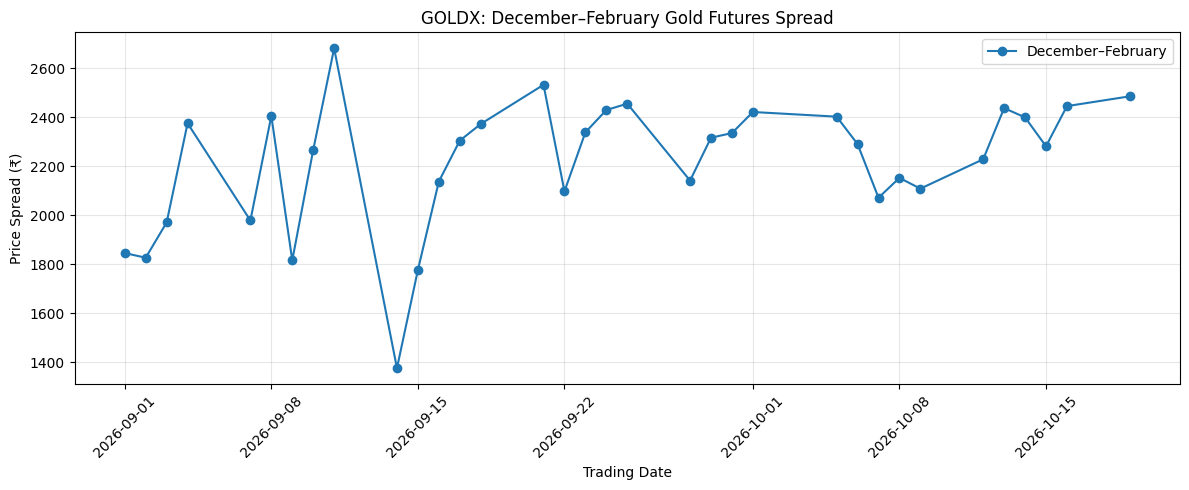

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    spreads.index,
    spreads["Dec_Feb_Spread"],
    marker="o",
    label="December–February"
)

plt.title("GOLDX: December–February Gold Futures Spread")
plt.xlabel("Trading Date")
plt.ylabel("Price Spread (₹)")
plt.grid(True, alpha=0.3)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Rolling Z-score

In [ ]:

spread_series = spreads["Dec_Feb_Spread"].copy()

window = 10

rolling_mean = spread_series.shift(1).rolling(
    window=window,
    min_periods=window
).mean()

rolling_std = spread_series.shift(1).rolling(
    window=window,
    min_periods=window
).std()

z_score = (spread_series - rolling_mean) / rolling_std

anomaly_results = pd.DataFrame({
    "Spread": spread_series,
    "Previous_Rolling_Mean": rolling_mean,
    "Previous_Rolling_Std": rolling_std,
    "Z_Score": z_score
})

anomaly_results["Potential_Anomaly"] = (
    anomaly_results["Z_Score"].abs() >= 2
)

print("Rolling Z-score results:")
display(anomaly_results.tail(15))

print("\nPotential anomalies:",
      anomaly_results["Potential_Anomaly"].sum())


Rolling Z-score results:


,Spread,Previous_Rolling_Mean,Previous_Rolling_Std,Z_Score,Potential_Anomaly
Date,,,,,
2026-09-28,2142.0,2182.5,358.808290,-0.112874,False
2026-09-29,2317.0,2259.1,223.907942,0.258588,False
2026-09-30,2336.0,2313.1,146.433489,0.156385,False
2026-10-01,2422.0,2332.9,132.886292,0.670498,False
2026-10-05,2403.0,2344.6,135.285870,0.431678,False
2026-10-06,2291.0,2347.6,136.314343,-0.415217,False
2026-10-07,2072.0,2323.4,120.281337,-2.090100,True
2026-10-08,2153.0,2320.8,125.847174,-1.333363,False
2026-10-09,2109.0,2302.2,136.179457,-1.418716,False



Potential anomalies: 1


Visualize the anomaly

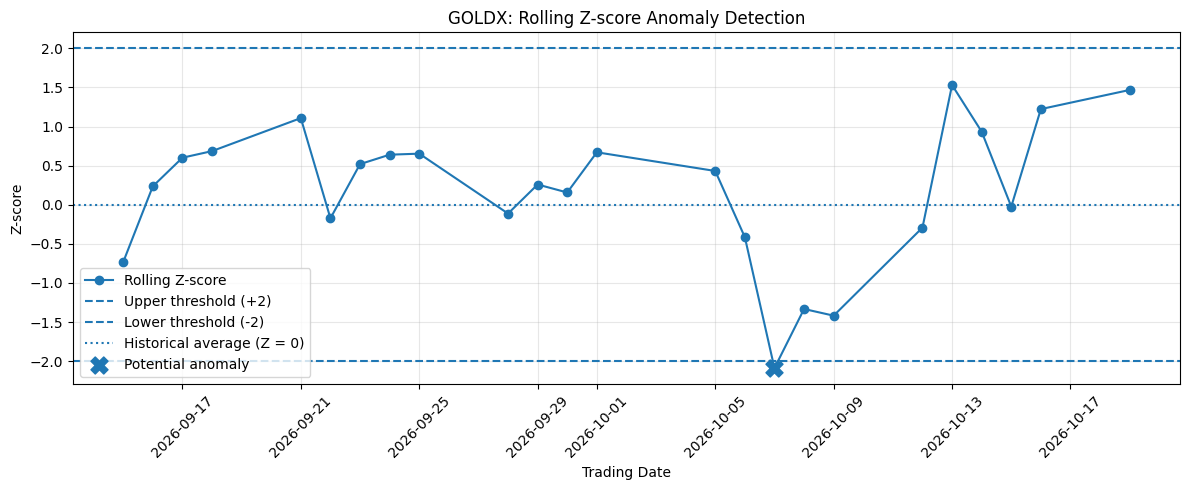

In [ ]:

plt.figure(figsize=(12, 5))

plt.plot(
    anomaly_results.index,
    anomaly_results["Z_Score"],
    marker="o",
    label="Rolling Z-score"
)

plt.axhline(
    2,
    linestyle="--",
    label="Upper threshold (+2)"
)

plt.axhline(
    -2,
    linestyle="--",
    label="Lower threshold (-2)"
)

plt.axhline(
    0,
    linestyle=":",
    label="Historical average (Z = 0)"
)

flagged = anomaly_results[
    anomaly_results["Potential_Anomaly"]
]

plt.scatter(
    flagged.index,
    flagged["Z_Score"],
    marker="X",
    s=150,
    label="Potential anomaly"
)

plt.title("GOLDX: Rolling Z-score Anomaly Detection")
plt.xlabel("Trading Date")
plt.ylabel("Z-score")
plt.grid(True, alpha=0.3)
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Whether our anomaly is robust

In [ ]:

spread_series = spreads["Dec_Feb_Spread"].copy()

window_sizes = [5, 10, 15]
comparison_results = []

for window in window_sizes:
    previous_mean = spread_series.shift(1).rolling(
        window=window,
        min_periods=window
    ).mean()

    previous_std = spread_series.shift(1).rolling(
        window=window,
        min_periods=window
    ).std()

    scores = (spread_series - previous_mean) / previous_std

    for date, score in scores.items():
        comparison_results.append({
            "Date": date,
            "Window": window,
            "Z_Score": score,
            "Potential_Anomaly": (
                pd.notna(score) and abs(score) >= 2
            )
        })

comparison_df = pd.DataFrame(comparison_results)

flagged_comparison = comparison_df[
    comparison_df["Potential_Anomaly"]
]

print("Potential anomalies by window:")
display(
    flagged_comparison.sort_values(["Window", "Date"])
)

print("\nNumber of flagged observations per window:")
display(
    comparison_df.groupby("Window")["Potential_Anomaly"]
    .sum()
    .rename("Flagged_Count")
    .to_frame()
)


Potential anomalies by window:


,Date,Window,Z_Score,Potential_Anomaly
9,2026-09-14,5,-2.488606,True
25,2026-10-07,5,-5.003742,True
29,2026-10-13,5,2.999938,True
59,2026-10-07,10,-2.090100,True



Number of flagged observations per window:


,Flagged_Count
Window,
5,3
10,1
15,0


Investigate the flagged dates

In [ ]:

spread_series = spreads["Dec_Feb_Spread"].dropna().sort_index()

flagged_dates = (
    flagged_comparison["Date"]
    .drop_duplicates()
    .sort_values()
    .tolist()
)

investigation = []

for date in flagged_dates:
    if date not in spread_series.index:
        continue

    position = spread_series.index.get_loc(date)
    current_spread = spread_series.loc[date]

    previous_values = spread_series.iloc[
        max(0, position - 10):position
    ]

    previous_mean = (
        previous_values.mean()
        if len(previous_values) == 10
        else float("nan")
    )

    row = {
        "Date": date,
        "Current_Spread": current_spread,
        "Previous_10_Mean": previous_mean,
        "Difference_From_Mean": (
            current_spread - previous_mean
        )
    }

    for horizon in [1, 3, 5]:
        future_position = position + horizon

        if future_position < len(spread_series):
            future_spread = spread_series.iloc[future_position]
            row[f"Change_After_{horizon}_Obs"] = (
                future_spread - current_spread
            )
        else:
            row[f"Change_After_{horizon}_Obs"] = float("nan")

    investigation.append(row)

investigation_df = pd.DataFrame(investigation)

print("Flagged-date investigation:")
display(investigation_df.round(2))


Flagged-date investigation:


,Date,Current_Spread,Previous_10_Mean,Difference_From_Mean,Change_After_1_Obs,Change_After_3_Obs,Change_After_5_Obs
0,2026-09-14,1376.0,NaN,NaN,401.0,929.0,1157.0
1,2026-10-07,2072.0,2323.4,-251.4,81.0,157.0,328.0
2,2026-10-13,2438.0,2247.4,190.6,-38.0,8.0,NaN


Audit each signal against its own window

In [ ]:

signal_audit = flagged_comparison[
    flagged_comparison["Potential_Anomaly"]
].copy()

signal_audit = signal_audit.sort_values(
    ["Date", "Window"]
).reset_index(drop=True)

audit_rows = []

spread_series = spreads["Dec_Feb_Spread"].dropna().sort_index()

for _, signal in signal_audit.iterrows():
    date = signal["Date"]
    window = int(signal["Window"])
    score = signal["Z_Score"]

    position = spread_series.index.get_loc(date)
    current_spread = spread_series.iloc[position]

    previous_values = spread_series.iloc[
        position - window:position
    ]

    if len(previous_values) == window:
        historical_mean = previous_values.mean()
        historical_std = previous_values.std()
    else:
        historical_mean = float("nan")
        historical_std = float("nan")

    audit_rows.append({
        "Date": date,
        "Window": window,
        "Z_Score": score,
        "Current_Spread": current_spread,
        "Historical_Mean": historical_mean,
        "Historical_Std": historical_std,
        "Difference_From_Mean": (
            current_spread - historical_mean
        )
    })

signal_audit_df = pd.DataFrame(audit_rows)

print("Signal audit:")
display(signal_audit_df.round(2))


Signal audit:


,Date,Window,Z_Score,Current_Spread,Historical_Mean,Historical_Std,Difference_From_Mean
0,2026-09-14,5,-2.49,1376.0,2230.0,343.16,-854.0
1,2026-10-07,5,-5.00,2072.0,2353.8,56.32,-281.8
2,2026-10-07,10,-2.09,2072.0,2323.4,120.28,-251.4
3,2026-10-13,5,3.00,2438.0,2170.8,89.07,267.2


Consolidated signal summary

In [ ]:

signal_summary = signal_audit_df.copy()

flag_counts = (
    signal_summary.groupby("Date")["Window"]
    .nunique()
    .rename("Windows_Flagged")
)

signal_summary = signal_summary.merge(
    flag_counts,
    on="Date",
    how="left"
)

signal_summary["Signal_Status"] = signal_summary[
    "Windows_Flagged"
].map(
    lambda count: (
        "Flagged by both windows"
        if count >= 2
        else "Flagged by one window"
    )
)

signal_summary = signal_summary.sort_values(
    ["Date", "Window"]
).reset_index(drop=True)

print("GOLDX signal summary:")
display(
    signal_summary[
        [
            "Date",
            "Window",
            "Z_Score",
            "Current_Spread",
            "Difference_From_Mean",
            "Windows_Flagged",
            "Signal_Status"
        ]
    ].round(2)
)


GOLDX signal summary:


,Date,Window,Z_Score,Current_Spread,Difference_From_Mean,Windows_Flagged,Signal_Status
0,2026-09-14,5,-2.49,1376.0,-854.0,1,Flagged by one window
1,2026-10-07,5,-5.00,2072.0,-281.8,2,Flagged by both windows
2,2026-10-07,10,-2.09,2072.0,-251.4,2,Flagged by both windows
3,2026-10-13,5,3.00,2438.0,267.2,1,Flagged by one window


Export the GOLDX datasets

In [ ]:

from pathlib import Path

output_dir = Path("goldx_outputs")
output_dir.mkdir(exist_ok=True)

gold_data.to_csv(
    output_dir / "gold_futures_cleaned.csv",
    index=False
)

spreads.reset_index().to_csv(
    output_dir / "gold_futures_spreads.csv",
    index=False
)

signal_summary.to_csv(
    output_dir / "goldx_signal_summary.csv",
    index=False
)

print("GOLDX files saved successfully!")

print("\nFiles created:")
for file_path in sorted(output_dir.glob("*.csv")):
    print(f"{file_path.name}: {file_path.stat().st_size:,} bytes")


GOLDX files saved successfully!

Files created:
gold_futures_cleaned.csv: 11,151 bytes
gold_futures_spreads.csv: 777 bytes
goldx_signal_summary.csv: 542 bytes


Check the output files

In [ ]:

for file_path in sorted(output_dir.glob("*.csv")):
    check_df = pd.read_csv(file_path)

    print(f"\nFile: {file_path.name}")
    print("Rows:", len(check_df))
    print("Columns:", check_df.columns.tolist())



File: gold_futures_cleaned.csv
Rows: 102
Columns: ['Date', 'Instrument Name', 'Symbol', 'Expiry Date', 'Option Type', 'Strike Price', 'Open', 'High', 'Low', 'Close', 'Previous Close', 'Volume(Lots)', "Volume(In 000's)", 'Value(Lacs)', 'Open Interest(Lots)']

File: gold_futures_spreads.csv
Rows: 34
Columns: ['Date', 'Dec_Feb_Spread', 'Feb_Apr_Spread']

File: goldx_signal_summary.csv
Rows: 4
Columns: ['Date', 'Window', 'Z_Score', 'Current_Spread', 'Historical_Mean', 'Historical_Std', 'Difference_From_Mean', 'Windows_Flagged', 'Signal_Status']


Analysis into reusable functions

In [ ]:

def calculate_spreads(gold_data):
    """
    Calculate same-day price spreads between gold futures contracts.
    Only compare contracts with positive trading volume.
    """

    data = gold_data.copy()

    data = data[
        data["Close"].notna()
        & (data["Volume(Lots)"] > 0)
    ]

    prices = data.pivot(
        index="Date",
        columns="Expiry Date",
        values="Close"
    )

    volumes = data.pivot(
        index="Date",
        columns="Expiry Date",
        values="Volume(Lots)"
    )

    dec_feb = (
        prices[pd.Timestamp("2027-02-05")]
        - prices[pd.Timestamp("2026-12-04")]
    ).where(
        (volumes[pd.Timestamp("2026-12-04")] > 0)
        & (volumes[pd.Timestamp("2027-02-05")] > 0)
    )

    feb_apr = (
        prices[pd.Timestamp("2027-04-05")]
        - prices[pd.Timestamp("2027-02-05")]
    ).where(
        (volumes[pd.Timestamp("2027-02-05")] > 0)
        & (volumes[pd.Timestamp("2027-04-05")] > 0)
    )

    return pd.DataFrame({
        "Dec_Feb_Spread": dec_feb,
        "Feb_Apr_Spread": feb_apr
    })


def calculate_rolling_zscore(spread_series, window=10):
    """
    Calculate Z-scores using only observations before each date.
    """

    previous_mean = spread_series.shift(1).rolling(
        window=window,
        min_periods=window
    ).mean()

    previous_std = spread_series.shift(1).rolling(
        window=window,
        min_periods=window
    ).std()

    z_score = (spread_series - previous_mean) / previous_std

    return pd.DataFrame({
        "Spread": spread_series,
        "Historical_Mean": previous_mean,
        "Historical_Std": previous_std,
        "Z_Score": z_score,
        "Potential_Anomaly": z_score.abs() >= 2
    })


print("GOLDX reusable functions defined successfully!")


GOLDX reusable functions defined successfully!


Test the functions

In [ ]:

spreads_function = calculate_spreads(gold_data)

zscore_function = calculate_rolling_zscore(
    spreads_function["Dec_Feb_Spread"],
    window=10
)

print("Recalculated spread shape:", spreads_function.shape)
print(
    "Valid December-February spreads:",
    spreads_function["Dec_Feb_Spread"].count()
)

print("\nLatest Z-score results:")
display(zscore_function.tail(10))

print(
    "\nPotential anomalies detected:",
    zscore_function["Potential_Anomaly"].sum()
)


Recalculated spread shape: (34, 2)
Valid December-February spreads: 34

Latest Z-score results:


,Spread,Historical_Mean,Historical_Std,Z_Score,Potential_Anomaly
Date,,,,,
2026-10-06,2291.0,2347.6,136.314343,-0.415217,False
2026-10-07,2072.0,2323.4,120.281337,-2.090100,True
2026-10-08,2153.0,2320.8,125.847174,-1.333363,False
2026-10-09,2109.0,2302.2,136.179457,-1.418716,False
2026-10-12,2229.0,2270.1,140.472575,-0.292584,False
2026-10-13,2438.0,2247.4,124.530407,1.530550,False
2026-10-14,2400.0,2277.0,131.667932,0.934168,False
2026-10-15,2282.0,2285.3,136.978547,-0.024091,False
2026-10-16,2446.0,2279.9,135.817238,1.222967,False



Potential anomalies detected: 1


Signal classification function

In [ ]:

def classify_spread_signals(zscore_df, threshold=2):
    """
    Classify spreads using historical rolling Z-scores.

    A negative Z-score means the spread is below its
    historical mean. A positive Z-score means it is above.
    """
    results = zscore_df.copy()

    results["Signal"] = np.select(
        [
            results["Z_Score"] <= -threshold,
            results["Z_Score"] >= threshold
        ],
        [
            "Potentially Low",
            "Potentially High"
        ],
        default="Normal"
    )

    results.loc[
        results["Z_Score"].isna(),
        "Signal"
    ] = "Insufficient History"

    return results


classified_signals = classify_spread_signals(
    zscore_function,
    threshold=2
)

print("GOLDX signal classification completed!")
display(
    classified_signals[
        [
            "Spread",
            "Historical_Mean",
            "Z_Score",
            "Potential_Anomaly",
            "Signal"
        ]
    ].tail(10)
)


GOLDX signal classification completed!


,Spread,Historical_Mean,Z_Score,Potential_Anomaly,Signal
Date,,,,,
2026-10-06,2291.0,2347.6,-0.415217,False,Normal
2026-10-07,2072.0,2323.4,-2.090100,True,Potentially Low
2026-10-08,2153.0,2320.8,-1.333363,False,Normal
2026-10-09,2109.0,2302.2,-1.418716,False,Normal
2026-10-12,2229.0,2270.1,-0.292584,False,Normal
2026-10-13,2438.0,2247.4,1.530550,False,Normal
2026-10-14,2400.0,2277.0,0.934168,False,Normal
2026-10-15,2282.0,2285.3,-0.024091,False,Normal
2026-10-16,2446.0,2279.9,1.222967,False,Normal


Summarize the signals

In [ ]:

signal_counts = (
    classified_signals["Signal"]
    .value_counts()
    .rename_axis("Signal")
    .reset_index(name="Count")
)

print("GOLDX Signal Summary")
display(signal_counts)

print("\nPotentially unusual dates:")
display(
    classified_signals[
        classified_signals["Potential_Anomaly"]
    ][
        ["Spread", "Historical_Mean", "Z_Score", "Signal"]
    ]
)


GOLDX Signal Summary


,Signal,Count
0,Normal,23
1,Insufficient History,10
2,Potentially Low,1



Potentially unusual dates:


,Spread,Historical_Mean,Z_Score,Signal
Date,,,,
2026-10-07,2072.0,2323.4,-2.0901,Potentially Low


Analyze both spreads

In [ ]:
dec_feb_analysis = calculate_rolling_zscore(
    spreads_function["Dec_Feb_Spread"],
    window=10
)

feb_apr_analysis = calculate_rolling_zscore(
    spreads_function["Feb_Apr_Spread"],
    window=10
)
dec_feb_classified = classify_spread_signals(
    dec_feb_analysis,
    threshold=2
)

feb_apr_classified = classify_spread_signals(
    feb_apr_analysis,
    threshold=2
)

print("DECEMBER-FEBRUARY")
print(
    "Valid spreads:",
    spreads_function["Dec_Feb_Spread"].count()
)
print(
    "Potential anomalies:",
    dec_feb_classified["Potential_Anomaly"].sum()
)

print("\nFEBRUARY-APRIL")
print(
    "Valid spreads:",
    spreads_function["Feb_Apr_Spread"].count()
)
print(
    "Potential anomalies:",
    feb_apr_classified["Potential_Anomaly"].sum()
)

print("\nFebruary-April signal results:")
display(
    feb_apr_classified[
        [
            "Spread",
            "Historical_Mean",
            "Z_Score",
            "Potential_Anomaly",
            "Signal"
        ]
    ].dropna(subset=["Spread"])
)


DECEMBER-FEBRUARY
Valid spreads: 34
Potential anomalies: 1

FEBRUARY-APRIL
Valid spreads: 16
Potential anomalies: 0

February-April signal results:


,Spread,Historical_Mean,Z_Score,Potential_Anomaly,Signal
Date,,,,,
2026-09-15,2660.0,NaN,NaN,False,Insufficient History
2026-09-18,1076.0,NaN,NaN,False,Insufficient History
2026-09-22,2785.0,NaN,NaN,False,Insufficient History
2026-09-23,2370.0,NaN,NaN,False,Insufficient History
2026-09-24,2692.0,NaN,NaN,False,Insufficient History
2026-09-28,3203.0,NaN,NaN,False,Insufficient History
2026-09-29,2192.0,NaN,NaN,False,Insufficient History
2026-09-30,3668.0,NaN,NaN,False,Insufficient History
2026-10-01,2198.0,NaN,NaN,False,Insufficient History


Combined signal table

In [ ]:

dec_feb_report = dec_feb_classified[
    ["Spread", "Z_Score", "Signal"]
].copy()

dec_feb_report["Contract_Pair"] = "December-February"

feb_apr_report = feb_apr_classified[
    ["Spread", "Z_Score", "Signal"]
].copy()

feb_apr_report["Contract_Pair"] = "February-April"

combined_signals = pd.concat(
    [dec_feb_report, feb_apr_report]
).reset_index()

combined_signals = combined_signals.rename(
    columns={"index": "Date"}
)

combined_signals = combined_signals[
    [
        "Date",
        "Contract_Pair",
        "Spread",
        "Z_Score",
        "Signal"
    ]
].sort_values(["Date", "Contract_Pair"])

print("GOLDX Combined Futures Signal Report")
display(combined_signals.tail(15))


GOLDX Combined Futures Signal Report


,Date,Contract_Pair,Spread,Z_Score,Signal
60,2026-10-08,February-April,NaN,NaN,Insufficient History
27,2026-10-09,December-February,2109.0,-1.418716,Normal
61,2026-10-09,February-April,2257.0,NaN,Insufficient History
28,2026-10-12,December-February,2229.0,-0.292584,Normal
62,2026-10-12,February-April,NaN,NaN,Insufficient History
29,2026-10-13,December-February,2438.0,1.530550,Normal
63,2026-10-13,February-April,2803.0,NaN,Insufficient History
30,2026-10-14,December-February,2400.0,0.934168,Normal
64,2026-10-14,February-April,3035.0,NaN,Insufficient History
31,2026-10-15,December-February,2282.0,-0.024091,Normal


Fix rolling Z-scores for missing spread dates

In [ ]:

def calculate_rolling_zscore(spread_series, window=10):
    """
    Calculate Z-scores from the previous `window` valid
    spread observations, excluding the current observation.
    Missing spread dates do not consume a window slot.
    """
    valid_spreads = spread_series.dropna()

    previous_mean = (
        valid_spreads.shift(1)
        .rolling(window=window, min_periods=window)
        .mean()
    )

    previous_std = (
        valid_spreads.shift(1)
        .rolling(window=window, min_periods=window)
        .std()
    )

    valid_zscore = (
        valid_spreads - previous_mean
    ) / previous_std

    valid_result = pd.DataFrame({
        "Spread": valid_spreads,
        "Historical_Mean": previous_mean,
        "Historical_Std": previous_std,
        "Z_Score": valid_zscore,
        "Potential_Anomaly": valid_zscore.abs() >= 2
    })

    result = valid_result.reindex(spread_series.index)

    result["Potential_Anomaly"] = (
        result["Potential_Anomaly"].fillna(False).astype(bool)
    )

    return result


print("Updated rolling Z-score function defined.")


Updated rolling Z-score function defined.


Recalculate and check both pairs

In [ ]:

dec_feb_analysis = calculate_rolling_zscore(
    spreads_function["Dec_Feb_Spread"], window=10
)

feb_apr_analysis = calculate_rolling_zscore(
    spreads_function["Feb_Apr_Spread"], window=10
)

dec_feb_classified = classify_spread_signals(dec_feb_analysis)
feb_apr_classified = classify_spread_signals(feb_apr_analysis)

print("DECEMBER-FEBRUARY")
print("Valid spreads:", dec_feb_analysis["Spread"].count())
print("Available Z-scores:", dec_feb_analysis["Z_Score"].count())
print("Potential anomalies:", dec_feb_analysis["Potential_Anomaly"].sum())

print("\nFEBRUARY-APRIL")
print("Valid spreads:", feb_apr_analysis["Spread"].count())
print("Available Z-scores:", feb_apr_analysis["Z_Score"].count())
print("Potential anomalies:", feb_apr_analysis["Potential_Anomaly"].sum())

print("\nFebruary-April recalculated results:")
display(
    feb_apr_classified[
        ["Spread", "Historical_Mean", "Z_Score", "Signal"]
    ].dropna(subset=["Spread"])
)


DECEMBER-FEBRUARY
Valid spreads: 34
Available Z-scores: 24
Potential anomalies: 1

FEBRUARY-APRIL
Valid spreads: 16
Available Z-scores: 6
Potential anomalies: 0

February-April recalculated results:


,Spread,Historical_Mean,Z_Score,Signal
Date,,,,
2026-09-15,2660.0,NaN,NaN,Insufficient History
2026-09-18,1076.0,NaN,NaN,Insufficient History
2026-09-22,2785.0,NaN,NaN,Insufficient History
2026-09-23,2370.0,NaN,NaN,Insufficient History
2026-09-24,2692.0,NaN,NaN,Insufficient History
2026-09-28,3203.0,NaN,NaN,Insufficient History
2026-09-29,2192.0,NaN,NaN,Insufficient History
2026-09-30,3668.0,NaN,NaN,Insufficient History
2026-10-01,2198.0,NaN,NaN,Insufficient History


Data quality and liquidity checks

In [ ]:
print("GOLDX DATA QUALITY AUDIT")
print("=" * 45)

print("\n1. Observations by expiry:")
display(
    gold_data.groupby("Expiry Date").agg(
        Total_Rows=("Date", "size"),
        Valid_Close=("Close", "count"),
        Positive_Volume=(
            "Volume(Lots)",
            lambda x: (x > 0).sum()
        ),
        Zero_Volume=(
            "Volume(Lots)",
            lambda x: (x == 0).sum()
        ),
        Missing_Close=("Close", lambda x: x.isna().sum())
    ).reset_index()
)

important_columns = [
    "Date", "Expiry Date", "Close",
    "Volume(Lots)", "Open Interest(Lots)"
]

print("\n2. Missing values in important columns:")
display(
    gold_data[important_columns].isna().sum()
    .rename("Missing_Count")
    .reset_index(name="Column")
)

print("\n3. Duplicate date-expiry combinations:")
print(
    gold_data.duplicated(
        subset=["Date", "Expiry Date"]
    ).sum()
)

print("\n4. Latest available observations:")
display(
    gold_data.sort_values("Date")
    .groupby("Expiry Date", group_keys=False)
    .tail(3)[
        [
            "Date", "Expiry Date", "Close",
            "Volume(Lots)", "Open Interest(Lots)"
        ]
    ]
    .sort_values(["Expiry Date", "Date"])
)


GOLDX DATA QUALITY AUDIT

1. Observations by expiry:


,Expiry Date,Total_Rows,Valid_Close,Positive_Volume,Zero_Volume,Missing_Close
0,2026-12-04,34,34,34,0,0
1,2027-02-05,34,34,34,0,0
2,2027-04-05,34,34,16,18,0



2. Missing values in important columns:


,index,Column
0,Date,0
1,Expiry Date,0
2,Close,0
3,Volume(Lots),0
4,Open Interest(Lots),0



3. Duplicate date-expiry combinations:
0

4. Latest available observations:


,Date,Expiry Date,Close,Volume(Lots),Open Interest(Lots)
93,2026-10-15,2026-12-04,147489.0,5618,17085
96,2026-10-16,2026-12-04,147918.0,5091,16717
99,2026-10-19,2026-12-04,147266.0,3865,16759
94,2026-10-15,2027-02-05,149771.0,136,647
97,2026-10-16,2027-02-05,150364.0,119,648
100,2026-10-19,2027-02-05,149752.0,100,657
95,2026-10-15,2027-04-05,152306.0,5,38
98,2026-10-16,2027-04-05,152306.0,0,38
101,2026-10-19,2027-04-05,152654.0,0,38


Liquidity audit function

In [ ]:

def build_pair_liquidity_report(gold_data):
    data = gold_data.copy()

    data["Date"] = pd.to_datetime(data["Date"])
    data["Expiry Date"] = pd.to_datetime(data["Expiry Date"])

    contract_pairs = {
        "December-February": (
            pd.Timestamp("2026-12-04"),
            pd.Timestamp("2027-02-05")
        ),
        "February-April": (
            pd.Timestamp("2027-02-05"),
            pd.Timestamp("2027-04-05")
        )
    }

    reports = []

    for pair_name, (near_expiry, far_expiry) in contract_pairs.items():
        pair_data = data[
            data["Expiry Date"].isin([near_expiry, far_expiry])
        ]

        volume_table = pair_data.pivot(
            index="Date",
            columns="Expiry Date",
            values="Volume(Lots)"
        )

        oi_table = pair_data.pivot(
            index="Date",
            columns="Expiry Date",
            values="Open Interest(Lots)"
        )

        close_table = pair_data.pivot(
            index="Date",
            columns="Expiry Date",
            values="Close"
        )

        report = pd.DataFrame(index=volume_table.index)

        report["Contract_Pair"] = pair_name
        report["Near_Volume"] = volume_table[near_expiry]
        report["Far_Volume"] = volume_table[far_expiry]
        report["Near_Open_Interest"] = oi_table[near_expiry]
        report["Far_Open_Interest"] = oi_table[far_expiry]

        report["Spread"] = (
            close_table[far_expiry] - close_table[near_expiry]
        )

        report["Both_Legs_Traded"] = (
            (report["Near_Volume"] > 0)
            & (report["Far_Volume"] > 0)
        )

        reports.append(report.reset_index())

    return pd.concat(reports, ignore_index=True)


liquidity_report = build_pair_liquidity_report(gold_data)

print("GOLDX Pair Liquidity Report")
display(
    liquidity_report.groupby("Contract_Pair").agg(
        Trading_Dates=("Date", "count"),
        Both_Legs_Traded=("Both_Legs_Traded", "sum"),
        Average_Near_Volume=("Near_Volume", "mean"),
        Average_Far_Volume=("Far_Volume", "mean"),
        Minimum_Far_Volume=("Far_Volume", "min")
    ).round(2).reset_index()
)

print("\nLatest February-April liquidity observations:")
display(
    liquidity_report[
        liquidity_report["Contract_Pair"] == "February-April"
    ][
        [
            "Date", "Near_Volume", "Far_Volume",
            "Near_Open_Interest", "Far_Open_Interest",
            "Spread", "Both_Legs_Traded"
        ]
    ].tail(8)
)


GOLDX Pair Liquidity Report


,Contract_Pair,Trading_Dates,Both_Legs_Traded,Average_Near_Volume,Average_Far_Volume,Minimum_Far_Volume
0,December-February,34,34,3705.76,97.32,8
1,February-April,34,16,97.32,2.29,0



Latest February-April liquidity observations:


,Date,Near_Volume,Far_Volume,Near_Open_Interest,Far_Open_Interest,Spread,Both_Legs_Traded
60,2026-10-08,147,0,519,34,1814.0,False
61,2026-10-09,165,1,535,33,2257.0,True
62,2026-10-12,66,0,542,33,4093.0,False
63,2026-10-13,172,2,603,35,2803.0,True
64,2026-10-14,242,16,644,38,3035.0,True
65,2026-10-15,136,5,647,38,2535.0,True
66,2026-10-16,119,0,648,38,1942.0,False
67,2026-10-19,100,0,657,38,2902.0,False


Combined report

In [ ]:
def build_liquidity_aware_signals(
    classified_signals,
    liquidity_report
):
    signals = classified_signals.reset_index().copy()

    if "Date" not in signals.columns:
        signals = signals.rename(
            columns={"index": "Date"}
        )

    signals["Date"] = pd.to_datetime(signals["Date"])

    pair_mapping = {
        "December-February": "Dec_Feb_Spread",
        "February-April": "Feb_Apr_Spread"
    }

    signal_frames = []

    for pair_name, spread_column in pair_mapping.items():
        pair_signals = signals[
            signals["Spread"].notna()
        ].copy()

        if pair_name == "December-February":
            pair_signals = dec_feb_classified.reset_index().copy()
        else:
            pair_signals = feb_apr_classified.reset_index().copy()

        if "Date" not in pair_signals.columns:
            pair_signals = pair_signals.rename(
                columns={"index": "Date"}
            )

        pair_signals["Date"] = pd.to_datetime(
            pair_signals["Date"]
        )

        pair_liquidity = liquidity_report[
            liquidity_report["Contract_Pair"] == pair_name
        ][
            ["Date", "Both_Legs_Traded",
             "Near_Volume", "Far_Volume"]
        ].copy()

        pair_liquidity["Date"] = pd.to_datetime(
            pair_liquidity["Date"]
        )

        merged = pair_signals.merge(
            pair_liquidity,
            on="Date",
            how="left"
        )

        merged["Contract_Pair"] = pair_name

        merged["Statistical_Anomaly"] = (
            merged["Z_Score"].abs() >= 2
        )

        merged["Potentially_Actionable"] = (
            merged["Statistical_Anomaly"]
            & merged["Both_Legs_Traded"].fillna(False)
        )

        signal_frames.append(merged)

    return pd.concat(signal_frames, ignore_index=True)


liquidity_aware_signals = build_liquidity_aware_signals(
    classified_signals,
    liquidity_report
)

print("GOLDX Liquidity-Aware Signal Summary")

display(
    liquidity_aware_signals.groupby("Contract_Pair").agg(
        Valid_Spreads=("Spread", "count"),
        Statistical_Anomalies=("Statistical_Anomaly", "sum"),
        Both_Legs_Traded=("Both_Legs_Traded", "sum"),
        Potentially_Actionable=("Potentially_Actionable", "sum")
    ).reset_index()
)

print("\nPotentially actionable candidates:")
display(
    liquidity_aware_signals[
        liquidity_aware_signals["Potentially_Actionable"]
    ][
        [
            "Date", "Contract_Pair", "Spread",
            "Z_Score", "Near_Volume", "Far_Volume"
        ]
    ]
)


GOLDX Liquidity-Aware Signal Summary


,Contract_Pair,Valid_Spreads,Statistical_Anomalies,Both_Legs_Traded,Potentially_Actionable
0,December-February,34,1,34,1
1,February-April,16,0,16,0



Potentially actionable candidates:


,Date,Contract_Pair,Spread,Z_Score,Near_Volume,Far_Volume
25,2026-10-07,December-February,2072.0,-2.0901,6454,201


Export the analysis reports

In [ ]:

from pathlib import Path

output_dir = Path("goldx_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

liquidity_report.to_csv(
    output_dir / "goldx_pair_liquidity.csv",
    index=False
)

liquidity_aware_signals.to_csv(
    output_dir / "goldx_liquidity_aware_signals.csv",
    index=False
)

candidates = liquidity_aware_signals[
    liquidity_aware_signals["Potentially_Actionable"]
].copy()

candidates.to_csv(
    output_dir / "goldx_potential_candidates.csv",
    index=False
)

print("GOLDX reports saved successfully!\n")

for file_path in sorted(output_dir.glob("*.csv")):
    print(f"{file_path.name}: {file_path.stat().st_size:,} bytes")


GOLDX reports saved successfully!

gold_futures_cleaned.csv: 11,151 bytes
gold_futures_spreads.csv: 777 bytes
goldx_liquidity_aware_signals.csv: 6,938 bytes
goldx_pair_liquidity.csv: 3,818 bytes
goldx_potential_candidates.csv: 300 bytes
goldx_signal_summary.csv: 542 bytes


GOLDX spread visualization

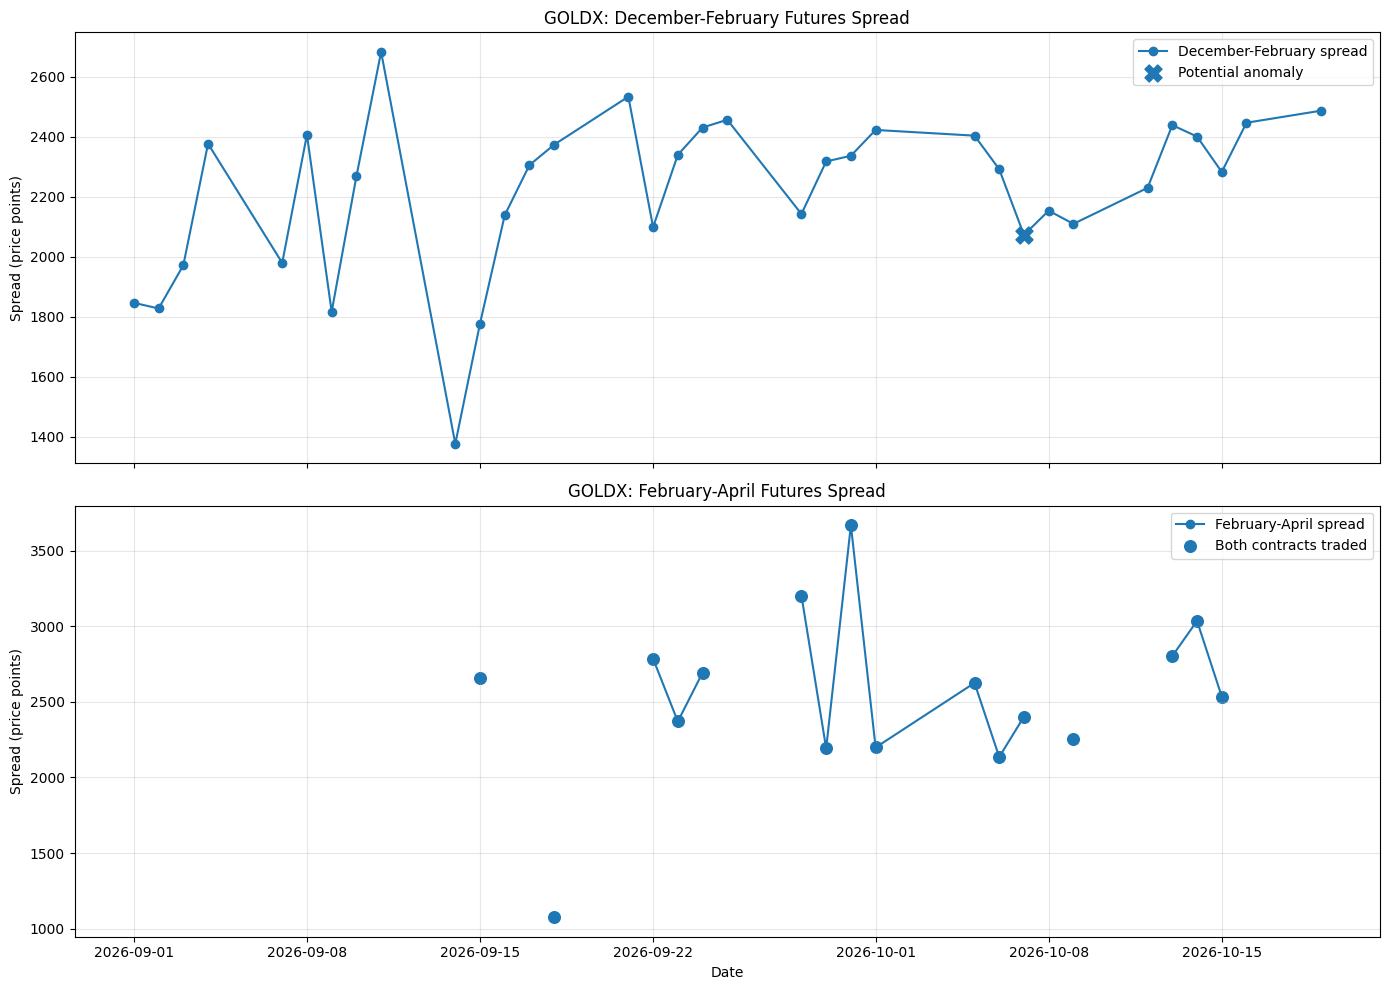

In [ ]:

import matplotlib.pyplot as plt
import pandas as pd

plot_data = spreads_function.copy()
plot_data.index = pd.to_datetime(plot_data.index)

dec_signals = dec_feb_classified.copy()
dec_signals.index = pd.to_datetime(dec_signals.index)

feb_signals = feb_apr_classified.copy()
feb_signals.index = pd.to_datetime(feb_signals.index)

fig, axes = plt.subplots(
    2, 1,
    figsize=(14, 10),
    sharex=True
)

axes[0].plot(
    plot_data.index,
    plot_data["Dec_Feb_Spread"],
    marker="o",
    label="December-February spread"
)

dec_anomalies = dec_signals[
    dec_signals["Potential_Anomaly"]
    & dec_signals["Spread"].notna()
]

axes[0].scatter(
    dec_anomalies.index,
    dec_anomalies["Spread"],
    marker="X",
    s=150,
    label="Potential anomaly"
)

axes[0].set_title(
    "GOLDX: December-February Futures Spread"
)
axes[0].set_ylabel("Spread (price points)")
axes[0].grid(True, alpha=0.3)
axes[0].legend()

axes[1].plot(
    plot_data.index,
    plot_data["Feb_Apr_Spread"],
    marker="o",
    label="February-April spread"
)

feb_liquidity = liquidity_report[
    liquidity_report["Contract_Pair"] == "February-April"
].copy()

feb_liquidity["Date"] = pd.to_datetime(
    feb_liquidity["Date"]
)

traded_dates = feb_liquidity.loc[
    feb_liquidity["Both_Legs_Traded"],
    "Date"
]

feb_traded = plot_data.loc[
    plot_data.index.isin(traded_dates),
    "Feb_Apr_Spread"
].dropna()

axes[1].scatter(
    feb_traded.index,
    feb_traded.values,
    marker="o",
    s=70,
    label="Both contracts traded"
)

axes[1].set_title(
    "GOLDX: February-April Futures Spread"
)
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Spread (price points)")
axes[1].grid(True, alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


Improve the February–April chart

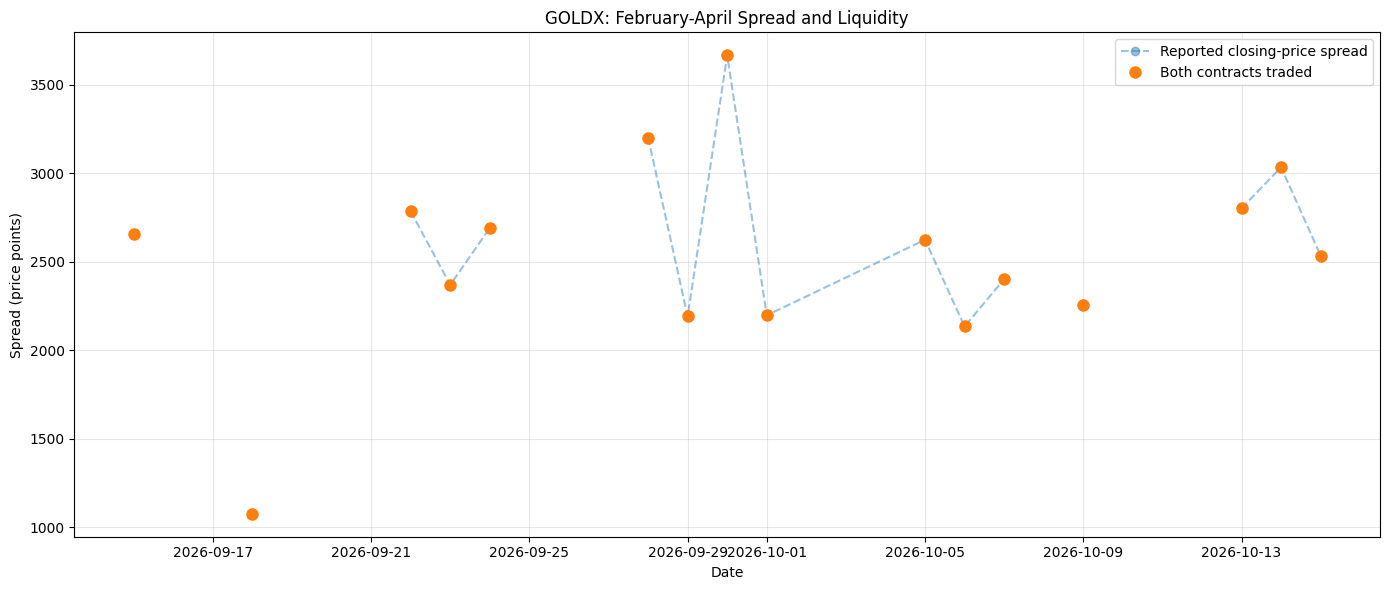

Reported spreads: 16
Spreads where both contracts traded: 16


In [ ]:

import matplotlib.pyplot as plt
import pandas as pd

plot_data = spreads_function.copy()
plot_data.index = pd.to_datetime(plot_data.index)

feb_liquidity = liquidity_report[
    liquidity_report["Contract_Pair"] == "February-April"
].copy()

feb_liquidity["Date"] = pd.to_datetime(
    feb_liquidity["Date"]
)

feb_liquidity = feb_liquidity.set_index("Date")

both_traded = (
    feb_liquidity["Both_Legs_Traded"]
    .reindex(plot_data.index)
    .fillna(False)
)

raw_spread = plot_data["Feb_Apr_Spread"]

liquid_spread = raw_spread.where(both_traded)

fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    raw_spread.index,
    raw_spread,
    marker="o",
    linestyle="--",
    alpha=0.45,
    label="Reported closing-price spread"
)

ax.plot(
    liquid_spread.index,
    liquid_spread,
    marker="o",
    linestyle="None",
    markersize=8,
    label="Both contracts traded"
)

ax.set_title(
    "GOLDX: February-April Spread and Liquidity"
)
ax.set_xlabel("Date")
ax.set_ylabel("Spread (price points)")
ax.grid(True, alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

print("Reported spreads:", raw_spread.count())
print("Spreads where both contracts traded:", liquid_spread.count())


Verify the liquidity counts

In [ ]:

print("GOLDX February-April count verification")
print("=" * 45)

pair = liquidity_report[
    liquidity_report["Contract_Pair"] == "February-April"
].copy()

print("Total recorded dates:", len(pair))
print("Both legs traded:", pair["Both_Legs_Traded"].sum())
print("At least one leg had zero volume:",
      (~pair["Both_Legs_Traded"]).sum())

print("\nDates where at least one leg had zero volume:")
display(
    pair.loc[
        ~pair["Both_Legs_Traded"],
        [
            "Date", "Near_Volume", "Far_Volume",
            "Spread", "Both_Legs_Traded"
        ]
    ]
)


GOLDX February-April count verification
Total recorded dates: 34
Both legs traded: 16
At least one leg had zero volume: 18

Dates where at least one leg had zero volume:


,Date,Near_Volume,Far_Volume,Spread,Both_Legs_Traded
34,2026-09-01,82,0,2427.0,False
35,2026-09-02,89,0,507.0,False
36,2026-09-03,64,0,-1776.0,False
37,2026-09-04,85,0,4401.0,False
38,2026-09-07,44,0,829.0,False
39,2026-09-08,14,0,316.0,False
40,2026-09-09,25,0,508.0,False
41,2026-09-10,38,0,1742.0,False
42,2026-09-11,35,0,238.0,False
43,2026-09-14,14,0,2769.0,False


GOLDX Pipeline Validation

In [ ]:

print("GOLDX PIPELINE VALIDATION")
print("=" * 45)

print("\n1. Spread availability")

print(
    "December-February:",
    spreads_function["Dec_Feb_Spread"].count()
)

print(
    "February-April:",
    spreads_function["Feb_Apr_Spread"].count()
)


print("\n2. Liquidity checks")

for pair_name in [
    "December-February",
    "February-April"
]:
    pair = liquidity_report[
        liquidity_report["Contract_Pair"] == pair_name
    ]

    print(
        f"{pair_name}: "
        f"{int(pair['Both_Legs_Traded'].sum())} / "
        f"{len(pair)} dates with both legs trading"
    )


print("\n3. Statistical anomalies")

for pair_name, result in [
    ("December-February", dec_feb_classified),
    ("February-April", feb_apr_classified)
]:
    anomalies = result[
        result["Potential_Anomaly"]
        & result["Spread"].notna()
    ]

    print(f"\n{pair_name}: {len(anomalies)} anomaly/anomalies")

    if anomalies.empty:
        print("No anomalies detected.")
    else:
        display(
            anomalies[
                ["Spread", "Z_Score", "Signal"]
            ]
        )


print("\n4. Potential candidate count")
print("Candidates:", len(candidates))


print("\n5. Data integrity")

assert gold_data.duplicated(
    subset=["Date", "Expiry Date"]
).sum() == 0, "Duplicate date-expiry records found!"

assert len(liquidity_report) == 68, (
    "Unexpected number of liquidity-report rows!"
)

feb_apr = liquidity_report[
    liquidity_report["Contract_Pair"] == "February-April"
]

assert feb_apr["Both_Legs_Traded"].sum() == 16, (
    "February-April liquidity count does not match!"
)

print("No duplicate date-expiry records.")
print("Liquidity report row count is correct.")
print("February-April trading-day count is correct.")

print("\nGOLDX validation completed!")


GOLDX PIPELINE VALIDATION

1. Spread availability
December-February: 34
February-April: 16

2. Liquidity checks
December-February: 34 / 34 dates with both legs trading
February-April: 16 / 34 dates with both legs trading

3. Statistical anomalies

December-February: 1 anomaly/anomalies


,Spread,Z_Score,Signal
Date,,,
2026-10-07,2072.0,-2.0901,Potentially Low



February-April: 0 anomaly/anomalies
No anomalies detected.

4. Potential candidate count
Candidates: 1

5. Data integrity
No duplicate date-expiry records.
Liquidity report row count is correct.
February-April trading-day count is correct.

GOLDX validation completed!


Inspect the October 7 candidate

In [ ]:

print("OCTOBER 7 CANDIDATE AUDIT")
print("=" * 45)

candidate_date = pd.Timestamp("2026-10-07")

candidate = dec_feb_classified.loc[
    dec_feb_classified.index == candidate_date
]

if candidate.empty:
    print("Candidate date not found in dec_feb_classified.")
else:
    print("\n1. Statistical signal")
    display(candidate)

print("\n2. Contract prices and liquidity")

date_data = gold_data[
    gold_data["Date"] == candidate_date
].copy()

display(
    date_data[
        [
            "Date",
            "Expiry Date",
            "Close",
            "Volume(Lots)",
            "Open Interest(Lots)"
        ]
    ].sort_values("Expiry Date")
)

print("\n3. Nearby December-February observations")

nearby = dec_feb_classified.loc[
    (dec_feb_classified.index >= "2026-09-30")
    & (dec_feb_classified.index <= "2026-10-14")
]

display(
    nearby[
        [
            "Spread",
            "Historical_Mean",
            "Historical_Std",
            "Z_Score",
            "Signal"
        ]
    ]
)


OCTOBER 7 CANDIDATE AUDIT

1. Statistical signal


,Spread,Historical_Mean,Historical_Std,Z_Score,Potential_Anomaly,Signal
Date,,,,,,
2026-10-07,2072.0,2323.4,120.281337,-2.0901,True,Potentially Low



2. Contract prices and liquidity


,Date,Expiry Date,Close,Volume(Lots),Open Interest(Lots)
75,2026-10-07,2026-12-04,149103.0,6454,16701
76,2026-10-07,2027-02-05,151175.0,201,521
77,2026-10-07,2027-04-05,153577.0,13,34



3. Nearby December-February observations


,Spread,Historical_Mean,Historical_Std,Z_Score,Signal
Date,,,,,
2026-09-30,2336.0,2313.1,146.433489,0.156385,Normal
2026-10-01,2422.0,2332.9,132.886292,0.670498,Normal
2026-10-05,2403.0,2344.6,135.285870,0.431678,Normal
2026-10-06,2291.0,2347.6,136.314343,-0.415217,Normal
2026-10-07,2072.0,2323.4,120.281337,-2.090100,Potentially Low
2026-10-08,2153.0,2320.8,125.847174,-1.333363,Normal
2026-10-09,2109.0,2302.2,136.179457,-1.418716,Normal
2026-10-12,2229.0,2270.1,140.472575,-0.292584,Normal
2026-10-13,2438.0,2247.4,124.530407,1.530550,Normal


Rolling-window sensitivity analysis

In [ ]:
windows = [5, 10, 15]

sensitivity_results = []

for window in windows:
    analysis = calculate_rolling_zscore(
        spreads_function["Dec_Feb_Spread"],
        window=window
    )

    classified = classify_spread_signals(
        analysis,
        threshold=2
    )

    candidate_date = pd.Timestamp("2026-10-07")

    if candidate_date in classified.index:
        row = classified.loc[candidate_date]

        sensitivity_results.append({
            "Window": window,
            "Date": candidate_date,
            "Spread": row["Spread"],
            "Historical_Mean": row["Historical_Mean"],
            "Historical_Std": row["Historical_Std"],
            "Z_Score": row["Z_Score"],
            "Signal": row["Signal"]
        })

sensitivity_df = pd.DataFrame(sensitivity_results)

print("ROLLING-WINDOW SENSITIVITY")
display(sensitivity_df.round(4))


ROLLING-WINDOW SENSITIVITY


,Window,Date,Spread,Historical_Mean,Historical_Std,Z_Score,Signal
0,5,2026-10-07,2072.0,2353.8000,56.3178,-5.0037,Potentially Low
1,10,2026-10-07,2072.0,2323.4000,120.2813,-2.0901,Potentially Low
2,15,2026-10-07,2072.0,2290.6667,187.8056,-1.1643,Normal


Full-dataset window comparison

In [ ]:
windows = [5, 10, 15]
window_comparison = []
window_anomaly_dates = []

for window in windows:
    analysis = calculate_rolling_zscore(
        spreads_function["Dec_Feb_Spread"],
        window=window
    )

    classified = classify_spread_signals(
        analysis,
        threshold=2
    )

    valid_zscores = classified["Z_Score"].dropna()

    anomalies = classified[
        classified["Potential_Anomaly"]
        & classified["Z_Score"].notna()
    ]

    window_comparison.append({
        "Window": window,
        "Valid_Z_Scores": len(valid_zscores),
        "Anomaly_Count": len(anomalies),
        "Low_Signals": (
            classified["Signal"] == "Potentially Low"
        ).sum(),
        "High_Signals": (
            classified["Signal"] == "Potentially High"
        ).sum()
    })

    for date, row in anomalies.iterrows():
        window_anomaly_dates.append({
            "Window": window,
            "Date": date,
            "Spread": row["Spread"],
            "Z_Score": row["Z_Score"],
            "Signal": row["Signal"]
        })

print("1. FULL-DATASET COMPARISON")
comparison_df = pd.DataFrame(window_comparison)
display(comparison_df)

print("\n2. ANOMALY DATES BY WINDOW")
if window_anomaly_dates:
    anomaly_dates_df = pd.DataFrame(window_anomaly_dates)
    display(anomaly_dates_df.round(4))
else:
    print("No anomalies detected for any window.")

print("\n3. INTERPRETATION")
print(
    "Compare the number and dates of signals across windows. "
    "More signals do not automatically mean better performance."
)


1. FULL-DATASET COMPARISON


,Window,Valid_Z_Scores,Anomaly_Count,Low_Signals,High_Signals
0,5,29,3,2,1
1,10,24,1,1,0
2,15,19,0,0,0



2. ANOMALY DATES BY WINDOW


,Window,Date,Spread,Z_Score,Signal
0,5,2026-09-14,1376.0,-2.4886,Potentially Low
1,5,2026-10-07,2072.0,-5.0037,Potentially Low
2,5,2026-10-13,2438.0,2.9999,Potentially High
3,10,2026-10-07,2072.0,-2.0901,Potentially Low



3. INTERPRETATION
Compare the number and dates of signals across windows. More signals do not automatically mean better performance.


Save baseline evaluation results

In [ ]:
from pathlib import Path

output_dir = Path("goldx_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

comparison_df.to_csv(
    output_dir / "goldx_window_comparison.csv",
    index=False
)

if "anomaly_dates_df" not in globals():
    anomaly_dates_df = pd.DataFrame(
        window_anomaly_dates,
        columns=[
            "Window", "Date", "Spread", "Z_Score", "Signal"
        ]
    )

anomaly_dates_df.to_csv(
    output_dir / "goldx_window_anomaly_dates.csv",
    index=False
)

baseline_report = """
GOLDX STATISTICAL BASELINE EVALUATION
=====================================

Contract pair: December 2026 - February 2027
Data period: September 1 - October 19, 2026
Recorded observations: 34

Method:
- Spread = February futures close - December futures close
- Rolling Z-score uses previous valid spread observations
- Anomaly threshold: absolute Z-score >= 2
- Current evaluation is exploratory, not a trading backtest

Window comparison:
- 5 observations: 29 valid Z-scores, 3 anomalies
- 10 observations: 24 valid Z-scores, 1 anomaly
- 15 observations: 19 valid Z-scores, 0 anomalies

October 7, 2026:
- Spread: 2072
- 5-observation Z-score: -5.0037
- 10-observation Z-score: -2.0901
- 15-observation Z-score: -1.1643

Interpretation:
The signal depends on the rolling-window length.
The current sample is small and does not establish
predictive accuracy or profitability.

Limitations:
- Limited historical observations
- No transaction-cost analysis
- No out-of-sample validation
- No trained or validated ML model
- Positive volume does not guarantee execution
"""

report_path = output_dir / "goldx_baseline_evaluation.txt"
report_path.write_text(baseline_report.strip(), encoding="utf-8")

print("Baseline evaluation saved successfully.")
print("\nFiles created:")

for file_path in [
    output_dir / "goldx_window_comparison.csv",
    output_dir / "goldx_window_anomaly_dates.csv",
    report_path
]:
    print(f"{file_path} — {file_path.stat().st_size:,} bytes")


Baseline evaluation saved successfully.

Files created:
goldx_outputs/goldx_window_comparison.csv — 96 bytes
goldx_outputs/goldx_window_anomaly_dates.csv — 258 bytes
goldx_outputs/goldx_baseline_evaluation.txt — 1,067 bytes


Historical data coverage audit

In [ ]:
print("GOLDX HISTORICAL DATA COVERAGE")
print("=" * 45)

print("\n1. Overall dataset")

print("Total records:", len(gold_data))
print("First date:", gold_data["Date"].min())
print("Last date:", gold_data["Date"].max())
print("Unique trading dates:", gold_data["Date"].nunique())
print("Unique expiry contracts:", gold_data["Expiry Date"].nunique())

print("\n2. Coverage by expiry")

coverage = (
    gold_data.groupby("Expiry Date")
    .agg(
        Records=("Date", "size"),
        Unique_Dates=("Date", "nunique"),
        First_Date=("Date", "min"),
        Last_Date=("Date", "max"),
        Positive_Volume_Days=(
            "Volume(Lots)",
            lambda x: (x > 0).sum()
        ),
        Zero_Volume_Days=(
            "Volume(Lots)",
            lambda x: (x == 0).sum()
        )
    )
    .reset_index()
    .sort_values("Expiry Date")
)

display(coverage)

print("\n3. Duplicate checks")

duplicate_records = gold_data.duplicated(
    subset=["Date", "Expiry Date"]
).sum()

print("Duplicate date-expiry records:", duplicate_records)

print("\n4. Date coverage note")

all_dates = sorted(gold_data["Date"].dropna().unique())

print(
    "The dataset contains",
    len(all_dates),
    "distinct recorded dates across all contracts."
)

print(
    "Note: gaps between dates may be weekends or market holidays; "
    "they are not automatically missing-data errors."
)


GOLDX HISTORICAL DATA COVERAGE

1. Overall dataset
Total records: 102
First date: 2026-09-01 00:00:00
Last date: 2026-10-19 00:00:00
Unique trading dates: 34
Unique expiry contracts: 3

2. Coverage by expiry


,Expiry Date,Records,Unique_Dates,First_Date,Last_Date,Positive_Volume_Days,Zero_Volume_Days
0,2026-12-04,34,34,2026-09-01,2026-10-19,34,0
1,2027-02-05,34,34,2026-09-01,2026-10-19,34,0
2,2027-04-05,34,34,2026-09-01,2026-10-19,16,18



3. Duplicate checks
Duplicate date-expiry records: 0

4. Date coverage note
The dataset contains 34 distinct recorded dates across all contracts.
Note: gaps between dates may be weekends or market holidays; they are not automatically missing-data errors.


Final application dataset

In [ ]:
from pathlib import Path
import pandas as pd
import numpy as np

output_dir = Path("goldx_outputs")
output_dir.mkdir(parents=True, exist_ok=True)

dec_app = dec_feb_classified.copy()
dec_app = dec_app.reset_index()

if "index" in dec_app.columns and "Date" not in dec_app.columns:
    dec_app = dec_app.rename(columns={"index": "Date"})

dec_app["Contract_Pair"] = "December 2026 - February 2027"

feb_app = feb_apr_classified.copy()
feb_app = feb_app.reset_index()

if "index" in feb_app.columns and "Date" not in feb_app.columns:
    feb_app = feb_app.rename(columns={"index": "Date"})

feb_app["Contract_Pair"] = "February 2027 - April 2027"

application_signals = pd.concat(
    [dec_app, feb_app],
    ignore_index=True
)

application_signals["Date"] = pd.to_datetime(
    application_signals["Date"]
)

liquidity_app = liquidity_report.copy()
liquidity_app["Date"] = pd.to_datetime(liquidity_app["Date"])

application_signals = application_signals.merge(
    liquidity_app[
        [
            "Date",
            "Contract_Pair",
            "Near_Volume",
            "Far_Volume",
            "Near_Open_Interest",
            "Far_Open_Interest",
            "Both_Legs_Traded"
        ]
    ],
    on=["Date", "Contract_Pair"],
    how="left",
    validate="one_to_one"
)

application_signals["Liquidity_Status"] = np.where(
    application_signals["Both_Legs_Traded"].eq(True),
    "Both contracts traded",
    "Insufficient liquidity / no trade"
)

application_signals = application_signals.sort_values(
    ["Date", "Contract_Pair"]
)

signals_path = output_dir / "goldx_application_signals.csv"
application_signals.to_csv(signals_path, index=False)

market_path = output_dir / "goldx_application_market_data.csv"
gold_data.to_csv(market_path, index=False)

print("GOLDX APPLICATION DATASETS CREATED")
print("=" * 45)
print("Signal rows:", len(application_signals))
print("Signal columns:", len(application_signals.columns))
print("Market data rows:", len(gold_data))
print("Duplicate signal keys:", application_signals.duplicated(
    subset=["Date", "Contract_Pair"]
).sum())

print("\nSignals by contract pair:")
display(
    application_signals.groupby("Contract_Pair").agg(
        Records=("Date", "size"),
        Valid_Spreads=("Spread", "count"),
        Both_Legs_Traded=("Both_Legs_Traded", "sum"),
        Anomalies=("Potential_Anomaly", "sum")
    ).reset_index()
)

print("\nSaved files:")
print(signals_path, "-", signals_path.stat().st_size, "bytes")
print(market_path, "-", market_path.stat().st_size, "bytes")


GOLDX APPLICATION DATASETS CREATED
Signal rows: 68
Signal columns: 14
Market data rows: 102
Duplicate signal keys: 0

Signals by contract pair:


,Contract_Pair,Records,Valid_Spreads,Both_Legs_Traded,Anomalies
0,December 2026 - February 2027,34,34,0,1
1,February 2027 - April 2027,34,16,0,0



Saved files:
goldx_outputs/goldx_application_signals.csv - 8778 bytes
goldx_outputs/goldx_application_market_data.csv - 11151 bytes


Fix the liquidity merge

In [ ]:
pair_mapping = {
    "December 2026 - February 2027": "December-February",
    "February 2027 - April 2027": "February-April"
}

application_signals["Liquidity_Pair"] = (
    application_signals["Contract_Pair"].map(pair_mapping)
)

liquidity_app = liquidity_report.copy()
liquidity_app["Date"] = pd.to_datetime(liquidity_app["Date"])

liquidity_columns = [
    "Near_Volume",
    "Far_Volume",
    "Near_Open_Interest",
    "Far_Open_Interest",
    "Both_Legs_Traded",
    "Liquidity_Status"
]

application_signals = application_signals.drop(
    columns=[
        col for col in liquidity_columns
        if col in application_signals.columns
    ]
)

application_signals = application_signals.merge(
    liquidity_app[
        [
            "Date",
            "Contract_Pair",
            "Near_Volume",
            "Far_Volume",
            "Near_Open_Interest",
            "Far_Open_Interest",
            "Both_Legs_Traded"
        ]
    ].rename(columns={"Contract_Pair": "Liquidity_Pair"}),
    on=["Date", "Liquidity_Pair"],
    how="left",
    validate="one_to_one"
)

application_signals["Liquidity_Status"] = np.where(
    application_signals["Both_Legs_Traded"].eq(True),
    "Both contracts traded",
    "Insufficient liquidity / no trade"
)

print("Unmatched liquidity records:",
      application_signals["Both_Legs_Traded"].isna().sum())

print("\nCorrected liquidity summary:")
display(
    application_signals.groupby("Contract_Pair").agg(
        Records=("Date", "size"),
        Valid_Spreads=("Spread", "count"),
        Both_Legs_Traded=("Both_Legs_Traded", "sum"),
        Anomalies=("Potential_Anomaly", "sum")
    ).reset_index()
)

application_signals.to_csv(
    output_dir / "goldx_application_signals.csv",
    index=False
)

print("\nCorrected application signals saved.")


Unmatched liquidity records: 0

Corrected liquidity summary:


,Contract_Pair,Records,Valid_Spreads,Both_Legs_Traded,Anomalies
0,December 2026 - February 2027,34,34,34,1
1,February 2027 - April 2027,34,16,16,0



Corrected application signals saved.
